# Step 4: Deploy and monitor

A model in a notebook helps nobody. In this step we:
1. Wrap the model in a **FastAPI** web service: send a photo, get flags back
2. Package it with **Docker** so it runs the same everywhere
3. Test it automatically with **GitHub Actions** on every push
4. **Monitor** it: log every prediction and use **Evidently** to notice when incoming photos change

```
seller uploads photo ──► POST /predict ──► CNN + white-border rule ──► {"tlgw": ..., "nwb": ..., "compliant": false}
                                │
                                └──► logs/predictions.csv ──► monitoring/monitor.py ──► flag rates + drift report
```

This notebook runs the API **inside Python** (no server or Docker needed), so it works on Colab.
The README shows how to run the real server and the Docker container on your laptop.

## 1. Setup

In [1]:
import os, sys
if 'google.colab' in sys.modules:
    !git clone -q https://github.com/sujatab1706-tech/my-project.git
    %cd my-project
else:
    os.chdir('..')
!pip install -q -r requirements.txt fastapi python-multipart httpx evidently
sys.path.insert(0, 'src'); sys.path.insert(0, '.')

## 2. What the API decides
The trained model (`models/cnn_mobilenet.keras`) and the thresholds from Step 3 (`models/thresholds.json`) are saved in the repo, so the API works straight away.

- **TLGW** = CNN probability ≥ its tuned threshold
- **NWB** = CNN says NWB **or** the strict white-border rule (`tol=6`) says NWB.
  Step 3 showed that the CNN misses off-white backgrounds and the rule catches them, so we use both.

In [2]:
print(open('models/thresholds.json').read())

{
  "tlgw": 0.4722,
  "nwb": 0.1476,
  "nwb_rule_tol": 6,
  "nwb_rule_min_fraction": 0.2
}


## 3. Call the API
`TestClient` sends real HTTP requests to the app without starting a server. It's exactly what our automated tests use.
We set `LOG_PATH` first so the demo logs go to their own file.

In [3]:
os.environ['LOG_PATH'] = 'logs/demo.csv'
from fastapi.testclient import TestClient
import api.app as app_module
client = TestClient(app_module.app)
client.get('/health').json()

I0000 00:00:1794910909.157604   12929 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794910909.158084   12929 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794910909.202673   12929 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794910910.253064   12929 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794910910.253447   12929 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


E0000 00:00:1794910911.632536   12929 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


{'status': 'ok',
 'model': 'models/cnn_mobilenet.keras',
 'thresholds': {'tlgw': 0.4722,
  'nwb': 0.1476,
  'nwb_rule_tol': 6,
  'nwb_rule_min_fraction': 0.2}}

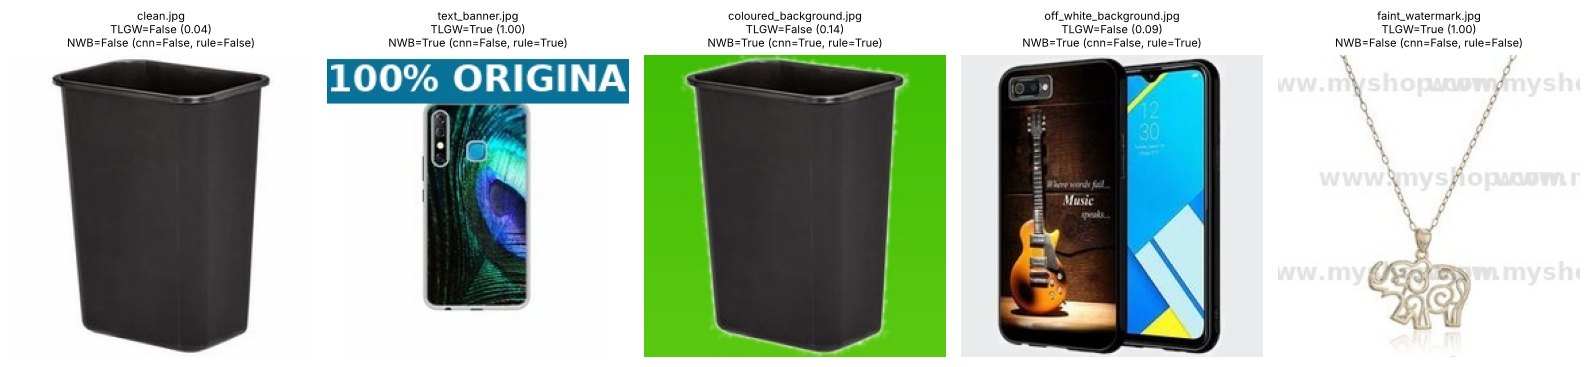

{
  "filename": "faint_watermark.jpg",
  "tlgw": {
    "flag": true,
    "probability": 1.0,
    "threshold": 0.4722
  },
  "nwb": {
    "flag": false,
    "probability": 0.0,
    "threshold": 0.1476,
    "cnn_flag": false,
    "rule_flag": false
  },
  "compliant": false,
  "image": {
    "width": 224,
    "height": 224,
    "brightness": 0.9729,
    "border_white_fraction": 0.9542
  },
  "latency_ms": 108.6
}


In [4]:
import json, matplotlib.pyplot as plt
from PIL import Image

samples = ['clean.jpg', 'text_banner.jpg', 'coloured_background.jpg', 'off_white_background.jpg', 'faint_watermark.jpg']
fig, axes = plt.subplots(1, len(samples), figsize=(16, 4))
for ax, name in zip(axes, samples):
    with open(f'samples/{name}', 'rb') as f:
        r = client.post('/predict', files={'file': (name, f, 'image/jpeg')}).json()
    ax.imshow(Image.open(f'samples/{name}')); ax.axis('off')
    ax.set_title(f"{name}\nTLGW={r['tlgw']['flag']} ({r['tlgw']['probability']:.2f})\n"
                 f"NWB={r['nwb']['flag']} (cnn={r['nwb']['cnn_flag']}, rule={r['nwb']['rule_flag']})", fontsize=8)
plt.tight_layout(); plt.show()
print(json.dumps(r, indent=2))  # the full answer for the last photo

Look at `off_white_background.jpg`: the CNN says no, but the rule catches it. That's the fix from Step 3, now running in the product.

The JSON answer also carries `image` statistics (brightness, share of white border pixels) and `latency_ms`.
They are written to the log for monitoring. We **never** store the photo itself, only numbers.

## 4. Monitoring
After deployment nobody labels the incoming photos, so **we can't measure accuracy any more**. Instead we watch two things:
1. **Flag rates:** what share of photos get flagged? A sudden jump or drop is suspicious.
2. **Data drift:** do the incoming photos (brightness, white border) and the model's probabilities look different from what it saw during development?

The **reference** is `monitoring/reference.csv`: the deployed model run over the validation images.
To create traffic, we need the Step 1 data and the Step 3 hard test set (rebuilt here if they're missing, about 10 minutes):

In [5]:
if not os.path.exists('data/processed/labels.csv'):
    !python src/download_abo.py --n 2000 --listing-files 4 --out data/raw
    !python src/make_violations.py --raw data/raw --out data/processed
if not os.path.exists('data/hard_test/labels.csv'):
    !python src/make_hard_test.py --processed data/processed --out data/hard_test

In [6]:
import pandas as pd
from pathlib import Path
from monitoring.monitor import flag_rate_check, drift_report

def send_traffic(folder, files, log_file):
    """Pretend sellers upload these photos. Each prediction is appended to log_file."""
    app_module.LOG_PATH = Path(log_file)
    if app_module.LOG_PATH.exists(): app_module.LOG_PATH.unlink()
    for f in files:
        with open(f'{folder}/images/{f}', 'rb') as fh:
            client.post('/predict', files={'file': (f, fh, 'image/jpeg')})
    return pd.read_csv(log_file)

reference = pd.read_csv('monitoring/reference.csv')
labels = pd.read_csv('data/processed/labels.csv')
normal_files = labels[labels.split == 'test'].sample(200, random_state=0).file
hard_files = pd.read_csv('data/hard_test/labels.csv').sample(200, random_state=0).file

### Day 1: normal traffic
Photos like the ones the model was built on (the test split).

In [7]:
day1 = send_traffic('data/processed', normal_files, 'logs/day1.csv')
rates, alerts = flag_rate_check(reference, day1)
display(rates)
drift1 = drift_report(reference, day1, 'monitoring/day1_drift.html')
display(drift1)
print('alerts:', alerts or 'none')

,flag,reference_rate,current_rate,change
0,tlgw_flag,0.305,0.305,-0.000
1,nwb_flag,0.379,0.365,-0.014


,column,method,score,threshold,drift
0,tlgw_prob,K-S p_value,0.2063,0.05,False
1,nwb_prob,K-S p_value,0.7992,0.05,False
2,brightness,K-S p_value,0.4492,0.05,False
3,border_white_fraction,K-S p_value,0.8903,0.05,False


alerts: none


For each column, Evidently runs a statistical test (Kolmogorov–Smirnov) asking *"could these two sets of numbers come from the same distribution?"*
A **p-value below 0.05** counts as drift.

⚠️ You may see a drift alarm here even though nothing is wrong. A p-value test at 0.05 raises a **false alarm about 1 time in 20** per column,
and we test 4 columns. The flag rates barely moved, so this is a "keep an eye on it" signal, not an emergency.
Real monitoring looks at several signals together, and over several days, before acting.

### Day 2: sellers start uploading different photos
Now we send the **hard test set**: off-white backgrounds, faint watermarks, tiny text.

In [8]:
day2 = send_traffic('data/hard_test', hard_files, 'logs/day2.csv')
rates, alerts = flag_rate_check(reference, day2)
display(rates)
drift2 = drift_report(reference, day2, 'monitoring/day2_drift.html')
display(drift2)
print('alerts:'); print('\n'.join('  ' + a for a in alerts) or '  none')

,flag,reference_rate,current_rate,change
0,tlgw_flag,0.305,0.235,-0.070
1,nwb_flag,0.379,0.200,-0.179


,column,method,score,threshold,drift
0,tlgw_prob,K-S p_value,0.1583,0.05,False
1,nwb_prob,K-S p_value,0.0000,0.05,True
2,brightness,K-S p_value,0.0000,0.05,True
3,border_white_fraction,K-S p_value,0.0000,0.05,True


alerts:
  nwb_flag rate moved from 38% to 20%


Now the alarms are loud and consistent:
- **brightness** and **border_white_fraction** drifted: the photos themselves look different (greyer backgrounds).
- **nwb_prob** drifted: the model's answers changed.
- the **NWB flag rate** moved a lot.

Notice that the monitor never knew the true labels. It still told us *something changed, go look*.
That's exactly what you want, because Step 3 showed this kind of data is where the model fails.

**What a team would do next:** take a sample of recent photos, label them by hand, measure precision and recall on them
(Step 3 tools), and if they've dropped, add those examples to the training data and retrain (Steps 1 and 2).

Open `monitoring/day2_drift.html` in your browser to see Evidently's full visual report.
In Colab: *Files panel → monitoring → right-click → Download*.

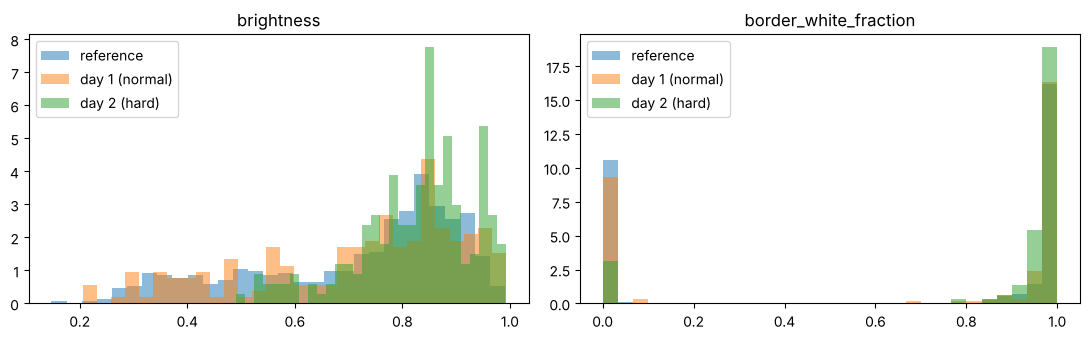

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, ['brightness', 'border_white_fraction']):
    ax.hist(reference[col], bins=30, alpha=0.5, density=True, label='reference')
    ax.hist(day1[col], bins=30, alpha=0.5, density=True, label='day 1 (normal)')
    ax.hist(day2[col], bins=30, alpha=0.5, density=True, label='day 2 (hard)')
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

## 5. Running it for real (on your laptop)
```bash
# 1. the API server
pip install -r requirements-api.txt
uvicorn api.app:app --reload          # then open http://127.0.0.1:8000/docs and try /predict

# 2. or in Docker
docker build -t image-compliance .
docker run -p 8000:8000 image-compliance

# 3. send some traffic and check monitoring
python monitoring/simulate_traffic.py --folder data/hard_test/images --limit 200
python monitoring/monitor.py --current logs/predictions.csv
```

## 6. Automatic checks (GitHub Actions)
`.github/workflows/ci.yml` runs on every push and pull request:
1. **tests**: `pytest` runs `tests/`, including API tests that use a tiny fake model so they finish in seconds
2. **docker**: builds the image, starts it, and sends a red-background photo to check that the real model flags NWB

## 🎉 Project complete (phase 1)
| Step | What you built |
|---|---|
| 1 | A labelled dataset made from free Amazon product photos |
| 2 | Baselines, a CNN from scratch, and MobileNetV2 transfer learning |
| 3 | Honest evaluation: precision/recall per label, thresholds, a hard test set, Grad-CAM |
| 4 | API, Docker, CI tests, and drift monitoring |

**Phase 2 ideas:** fix the weaknesses found in Step 3 (add off-white and tiny-text examples, then retrain), then add the
**brand infringement** and **prurience** labels.